# Lab 13-09 · The Smith Chart and Impedance Matching

Companion to [chapter 13-09](../../chapters/13-09-smith-chart-and-matching.md). Four parts: drawing a Smith chart and moving points on it; L-network design with both solutions; single-stub matching; and multi-section matching against the Bode–Fano limit. Run the cells in order.

In [1]:
import cmath, math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
Z0 = 50.0
gam = lambda Z: (Z - Z0) / (Z + Z0)

def smith(ax):
    th = np.linspace(0, 2 * np.pi, 400); ax.plot(np.cos(th), np.sin(th), 'k', lw=1)
    for r in (0.2, 0.5, 1, 2, 5):
        g = gam(Z0 * (r + 1j * np.linspace(-60, 60, 4001))); ax.plot(g.real, g.imag, color='0.75', lw=0.6)
    for x in (0.2, 0.5, 1, 2, 5):
        for s in (1, -1):
            g = gam(Z0 * (np.linspace(0, 60, 4001) + 1j * s * x)); ax.plot(g.real, g.imag, color='0.75', lw=0.6)
    ax.plot([-1, 1], [0, 0], color='0.75', lw=0.6); ax.set_aspect('equal'); ax.axis('off')

## Part 1 · Points and moves

Plot several loads, their |Γ| circles, and their paths as a line is added toward the generator.

**Predict first:** after λ/4 of line, where does $z$ = 2 + j1 land? After λ/2?

(100+50j): |Gamma| = 0.4472; after lambda/4 Z = 20.00-10.00j ohm (Z0^2/ZL = 20.00-10.00j)
(25-50j): |Gamma| = 0.6202; after lambda/4 Z = 20.00+40.00j ohm (Z0^2/ZL = 20.00+40.00j)
12.5: |Gamma| = 0.6000; after lambda/4 Z = 200.00 ohm (Z0^2/ZL = 200.00)


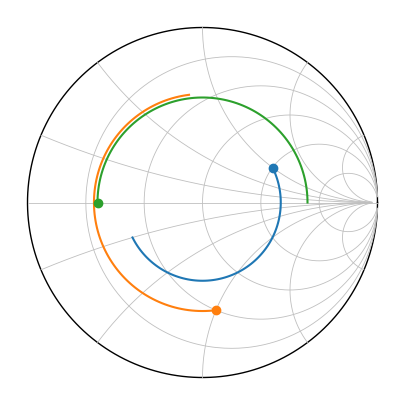

In [2]:
fig, ax = plt.subplots(figsize=(5, 5)); smith(ax)
for ZL, col in ((100 + 50j, 'C0'), (25 - 50j, 'C1'), (12.5, 'C2')):
    g = gam(ZL)
    path = g * np.exp(-2j * np.linspace(0, np.pi / 2, 100))      # lambda/4 toward the generator
    ax.plot(path.real, path.imag, color=col); ax.plot(g.real, g.imag, 'o', color=col)
    zq = Z0 * (1 - g) / (1 + g)
    print(f"{ZL}: |Gamma| = {abs(g):.4f}; after lambda/4 Z = {zq:.2f} ohm (Z0^2/ZL = {Z0**2 / ZL:.2f})")
plt.show()

## Part 2 · L-networks

Design both L-network solutions (low-pass and high-pass) that match a resistance $R_L$ to 50 Ω at $f_0$, and plot |Γ| against frequency.

**Predict first:** which of the two forms has the wider band for $R_L$ = 10 Ω?

low-pass: Q = 2.000, |Gamma| < 0.1 from 2.261 to 2.531 GHz
high-pass: Q = 2.000, |Gamma| < 0.1 from 2.276 to 2.547 GHz


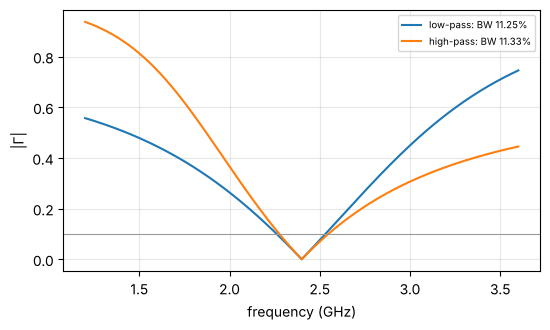

In [3]:
def lmatch(RL, f0, kind):
    Rh, Rl = max(RL, Z0), min(RL, Z0); Q = math.sqrt(Rh / Rl - 1); w0 = 2 * math.pi * f0
    X, B = Q * Rl, Q / Rh
    def zin(f):
        w = 2 * math.pi * f
        if kind == 'low-pass':     # series L at the low side, shunt C at the high side
            Zser = 1j * w * X / w0; Ysh = 1j * w * B / w0
        else:                      # series C, shunt L
            Zser = -1j * X * w0 / w; Ysh = -1j * B * w0 / w
        if RL < Z0:
            return 1 / (1 / (RL + Zser) + Ysh)
        return 1 / (1 / RL + Ysh) + Zser
    return zin, Q

f = np.linspace(1.2e9, 3.6e9, 1201)
fig, ax = plt.subplots(figsize=(5.6, 3.4))
for kind in ('low-pass', 'high-pass'):
    zin, Q = lmatch(10, 2.4e9, kind)
    G = np.array([abs(gam(zin(ff))) for ff in f])
    lo = brentq(lambda ff: abs(gam(zin(ff))) - 0.1, 1.2e9, 2.4e9); hi = brentq(lambda ff: abs(gam(zin(ff))) - 0.1, 2.4e9, 3.6e9)
    ax.plot(f / 1e9, G, label=f"{kind}: BW {100 * (hi - lo) / 2.4e9:.2f}%")
    print(f"{kind}: Q = {Q:.3f}, |Gamma| < 0.1 from {lo / 1e9:.3f} to {hi / 1e9:.3f} GHz")
ax.axhline(0.1, color='0.6', lw=0.8); ax.set_xlabel('frequency (GHz)'); ax.set_ylabel('|Γ|'); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Part 3 · Single-stub matching

For a load, rotate its admittance toward the generator until $g$ = 1, then find the shorted stub that cancels the susceptance. Plot the path for Example 13-09.5's 25 − j50 Ω load.

**Predict first:** are the two required susceptances equal and opposite?

d = 0.06313 lambda: y = 1.0000+1.5811j; shorted stub 0.08975 lambda
d = 0.20666 lambda: y = 1.0000-1.5811j; shorted stub 0.41025 lambda


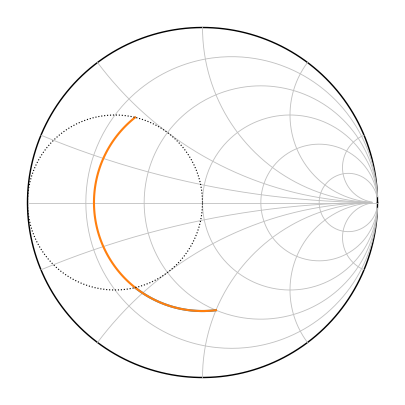

In [4]:
def zline(ZL, frac):
    t = math.tan(2 * math.pi * frac); return Z0 * (ZL + 1j * Z0 * t) / (Z0 + 1j * ZL * t)
ZL = 25 - 50j
ds = np.linspace(0.0005, 0.4995, 2000)
g_re = np.array([(Z0 / zline(ZL, d)).real - 1 for d in ds])
sols = [brentq(lambda d: (Z0 / zline(ZL, d)).real - 1, ds[i], ds[i + 1]) for i in range(len(ds) - 1)
        if g_re[i] * g_re[i + 1] < 0 and abs(g_re[i]) < 3]
fig, ax = plt.subplots(figsize=(5, 5)); smith(ax)
for d in sols:
    y = Z0 / zline(ZL, d); b = y.imag
    l = (math.atan(1 / b) / (2 * math.pi)) % 0.5        # shorted stub: y = -j cot(beta l) must equal -jb
    print(f"d = {d:.5f} lambda: y = {y:.4f}; shorted stub {l:.5f} lambda")
    path = np.array([gam(zline(ZL, x)) for x in np.linspace(0, d, 100)])
    ax.plot(path.real, path.imag)
th = np.linspace(0, 2 * np.pi, 200); gc = -0.5 + 0.5 * np.exp(1j * th)   # g = 1 circle (admittance), on the Gamma plane
ax.plot(gc.real, gc.imag, 'k:', lw=0.8)
plt.show()

## Part 4 · More sections, and the Bode–Fano wall

Match 10 Ω to 50 Ω at 2.4 GHz with one, two and three low-pass L-sections through geometric intermediate resistances, and compare their bandwidths. Then compute the Bode–Fano bound for a 50 Ω ∥ 1 pF load at several return-loss targets.

**Predict first:** roughly how wide is the three-section band for |Γ| < 0.1?

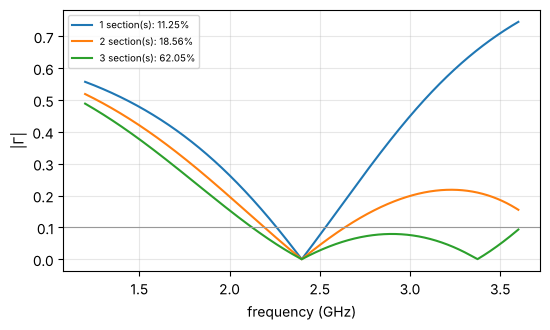

Bode-Fano, 50 ohm || 1 pF, return loss 10 dB: bandwidth at most 8.686 GHz
Bode-Fano, 50 ohm || 1 pF, return loss 15 dB: bandwidth at most 5.791 GHz
Bode-Fano, 50 ohm || 1 pF, return loss 20 dB: bandwidth at most 4.343 GHz
Bode-Fano, 50 ohm || 1 pF, return loss 30 dB: bandwidth at most 2.895 GHz


In [5]:
def cascade(n, f0=2.4e9, RL=10.0):
    Rs = [RL * (Z0 / RL) ** (k / n) for k in range(n + 1)]
    w0 = 2 * math.pi * f0; secs = []
    for Rl, Rh in zip(Rs[:-1], Rs[1:]):
        Q = math.sqrt(Rh / Rl - 1); secs.append((Q * Rl / w0, Q / Rh / w0))
    def zin(f):
        w = 2 * math.pi * f; Z = RL
        for L, C in secs:
            Z = 1 / (1 / (Z + 1j * w * L) + 1j * w * C)
        return Z
    return zin
fig, ax = plt.subplots(figsize=(5.6, 3.4))
for n in (1, 2, 3):
    zin = cascade(n)
    lo = brentq(lambda ff: abs(gam(zin(ff))) - 0.1, 1e9, 2.4e9); hi = brentq(lambda ff: abs(gam(zin(ff))) - 0.1, 2.4e9, 6e9)
    ax.plot(f / 1e9, [abs(gam(zin(ff))) for ff in f], label=f"{n} section(s): {100 * (hi - lo) / 2.4e9:.2f}%")
ax.axhline(0.1, color='0.6', lw=0.8); ax.set_xlabel('frequency (GHz)'); ax.set_ylabel('|Γ|'); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
for RLdB in (10, 15, 20, 30):
    Gm = 10 ** (-RLdB / 20)
    print(f"Bode-Fano, 50 ohm || 1 pF, return loss {RLdB} dB: bandwidth at most {1 / (2 * 50 * 1e-12 * math.log(1 / Gm)) / 1e9:.3f} GHz")

## What to notice

- A quarter wavelength of line carries any point half way round its |Γ| circle: impedance inversion.
- The low-pass and high-pass L-networks have the same Q and nearly the same bandwidth; the choice is about harmonics and DC paths.
- The two stub solutions need equal and opposite susceptances.
- Each added section lowers the Q per section and widens the band (about 11%, 19% and 62% for one, two and three sections here), but no number of sections can beat the Bode–Fano bound for a reactive load.